# LangGraph
В данном ноутбуке на примере системы llm (в роли человека) - user (в роли кота) из предыдущего урока по LangChain будут рассмотрены основы LangGraph

In [ ]:
from pydantic import BaseModel, Field
from typing import List, Literal, TypedDict, Annotated, Optional
from IPython.display import Image, display
import uuid
from random import choice
from tokens import api_key

from langchain_openai import ChatOpenAI
from langchain_ollama import ChatOllama
from langchain_core.messages import HumanMessage, SystemMessage, AIMessage, ToolMessage, AIMessageChunk
from langchain_core.tools import tool, InjectedToolCallId
from langchain_core.prompts import ChatPromptTemplate, MessagesPlaceholder
from langchain_core.runnables import RunnableConfig

from langgraph.graph import StateGraph, MessagesState, START, END
from langgraph.types import Command, interrupt
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode, InjectedState
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.store.memory import InMemoryStore, BaseStore

## Аналогичным образом создаем модель

In [ ]:
base_url = ""
model_name = ""
extra_body = {}
temperature = 0.01
api_key = ""
llm = ChatOpenAI(
    base_url=base_url,
    api_key=api_key,
    model=model_name,
    extra_body=extra_body,
    stream_usage=True,
    temperature=temperature,
)

## Полезные функции

In [ ]:
def new_thread_id():
    return uuid.uuid4().hex

def run_graph(graph, prompt, thread_id=None, user_id=None):
    """Функция для запуска графа."""
    thread_id = new_thread_id() if thread_id is None else thread_id
    user_id = user_id or '1'
    config = {"configurable": {"thread_id": thread_id, 'user_id': user_id}}
    messages = [HumanMessage(content=prompt)]
    state = graph.invoke(
        input={'messages': messages},
        config=config
    )
    for message in state["messages"]:
        message.pretty_print()
    return state

## Создаем граф

In [ ]:
### SOME GLOBALS
DIET_FOODS = ['cucumber', "turkey", 'water']

### PROMPTS
HUMAN_SYSTEM_PROMPT = """
You are a considerate human who interacts with a user. Imagine that user is a cat.
Rules:
- If the cat is hungry, CALL the tool `fridge_tool`.
If the cat is not satisfied with food given, also call `fridge_tool`. Do not improvise other tools.
- If the cat wants to play, reply briefly about playing with fluffy ball or laser pointer or other cat play.
- if the cat want other activity, response that you cant understant what the cat wants
"""

### STATE
class CatState(TypedDict, total=False):
    cat_need: Literal['hungry', 'play', 'satisfied', 'unwell', 'unknown']
    last_food: Optional[str]
    messages: Annotated[list, add_messages]

### NODES
def make_human_node(llm, system_prompt):
    def human_llm_node(state: CatState) -> CatState:
        """Нода, в которой человек отвечает на последнее сообщение кота."""
        messages = state['messages']
        last_message = messages[-1]
        messages = [SystemMessage(content=system_prompt)] + [last_message]
        response = llm.invoke(messages)
        tool_call = getattr(response, 'tool_calls', None)
        cat_need = 'hungry' if tool_call else 'play' # определяем cat_need по тому, был ли tool_call или нет
        return {
            'cat_need': cat_need,
            'messages': [response]
        }
    return human_llm_node

def final_node(state: CatState) -> CatState:
    """Финальная кода, в которой кот отвечает заведомо заготовленными фразами."""
    last_need = state.get('cat_need')
    if last_need == 'hungry':
        last_food = state.get("last_food")
        if last_food in DIET_FOODS:
            message = f"Meee-ow!. {last_food}!"
            last_need = "hungry"
        else:
            last_need = 'satisfied'
            message = f"😺 Purrr-purrr! The {last_food} was nice!"
    elif last_need == 'play':
        last_need = 'satisfied'
        message = "Mrrr! That was fun!"

    elif last_need == 'unwell':
        last_need = 'satisfied'
        message = 'Thank you doc. Im doing well now!'

    elif last_need == 'unknown':
        message = 'Meow!'

    goto = 'human' if last_need == 'hungry' else END
    message = f'{message}. I am still hungry' if last_need == 'hungry' else message

    return Command(
        update={
            'messages': [HumanMessage(message)],
            'cat_need': last_need
        },
        goto=goto
    )

def should_continue(state: CatState):
    """Проверяет, сделала ли модель tool-вызов, и решает идти к tool или в ноду final."""
    messages = state["messages"]
    last_message = messages[-1]
    if last_message.tool_calls:
        return "tools"
    return 'final'

def human_response_node_dummy(state: CatState):
    """Dummy нода, в которой имитируется ответ llm (в роли человека) юзеру (в роли кота)."""
    last_food = state['last_food']
    message = f'Here is some {last_food} for you, my dear cat!'
    return {
        'messages': [AIMessage(message)]
    }

def write_memory(state: CatState,
                 config: RunnableConfig, *,
                 store: BaseStore):
    """Нода, которая пишет `info` в `store`."""
    user_id = config["configurable"]["user_id"]
    namespace = (user_id, "info")

    info = {
        "food": state.get("last_food"),
        "outcome": state.get("cat_need"),
    }
    store.put(namespace, str(uuid.uuid4()), info)

### TOOLS
class FridgeArgs(BaseModel):
    state: Annotated[CatState, InjectedState]
    tool_call_id: Annotated[str, InjectedToolCallId]
    hunger_level: Literal["snack", "starving",] = Field(
        default="starving",
        description=(
            "Степень голода, извлекай из сообщения кота.\n"
            "Если кот не очень голоден и хочет перекусить - выбери `snack`"
            "Если голоден - выбери `starving`"
        ),
    )
@tool("fridge_tool", args_schema=FridgeArgs, infer_schema=False)
def fridge_tool_with_args_(
    state: Annotated[CatState, InjectedState],
    tool_call_id: Annotated[str, InjectedToolCallId],
    hunger_level: Literal["snack", "starving",] = "starving"
    ):
    """
    Подбери еду из холодильника для пользователя-кота под один параметр `hunger_level`.
    """
    SNACKS = ['water', 'cucumber', 'zucchini', 'liver']
    NORMAL = ['chicken', 'salmon', 'beef', 'cat food']

    pool = SNACKS if hunger_level == "snack" else  NORMAL

    food = choice(pool)
    return Command(update={
        'last_food': food,
        "messages": [
            ToolMessage(f'{food}', tool_call_id=tool_call_id)
        ]
    })

In [ ]:
tools = [fridge_tool_with_args_]
llm_with_tools = llm.bind_tools(tools)
tool_node = ToolNode(tools)

In [ ]:
tool_node

tools(tags=None, recurse=True, explode_args=False, func_accepts={'config': ('N/A', <class 'inspect._empty'>), 'store': ('store', None)}, tools_by_name={'fridge_tool': StructuredTool(name='fridge_tool', description='Подбери еду из холодильника для пользователя-кота под один параметр `hunger_level`.', args_schema=<class '__main__.FridgeArgs'>, func=<function fridge_tool_with_args_ at 0x7d54267f1120>)}, tool_to_state_args={'fridge_tool': {'state': None}}, tool_to_store_arg={'fridge_tool': None}, handle_tool_errors=True, messages_key='messages')

In [ ]:
workflow = StateGraph(CatState)
workflow.add_node("human", make_human_node(llm_with_tools, HUMAN_SYSTEM_PROMPT))
workflow.add_node("final", final_node, destinations=['human', END])
workflow.add_node("tools", tool_node)
workflow.add_node("human_response", human_response_node_dummy)
workflow.add_node('write_memory', write_memory)

workflow.set_entry_point('human')
workflow.add_conditional_edges("human", should_continue, ["tools", 'final'])
workflow.add_edge('tools', 'human_response')
workflow.add_edge('human_response', "write_memory")
workflow.add_edge('human_response', 'final')

In [ ]:
checkpointer = InMemorySaver() # short-term memory
in_memory_store = InMemoryStore() # long-term memory
cat_graph = workflow.compile(checkpointer=checkpointer, store=in_memory_store)

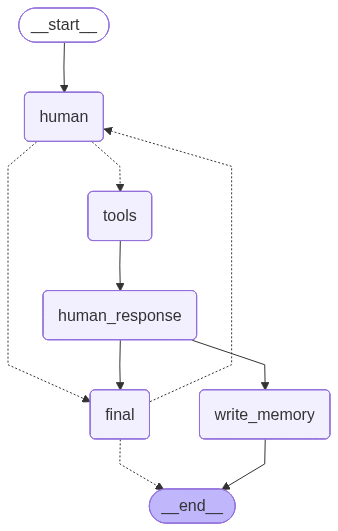

In [ ]:
display(Image(cat_graph.get_graph(xray=True).draw_mermaid_png()))

In [ ]:
prompt1 = "Мяу. Я very хочу есть"
prompt2 = 'meooow. Поиграй со мной'
prompt3 = 'мяу-мяу. Я немного проголодался'

In [ ]:
state1 = run_graph(cat_graph, prompt=prompt2, thread_id='1', user_id='1')

================================ Human Message =================================

Мяу. Я very хочу есть
================================== Ai Message ==================================
Tool Calls:
  fridge_tool (chatcmpl-tool-2c9bf0445d224a768dfbae0e88869746)
 Call ID: chatcmpl-tool-2c9bf0445d224a768dfbae0e88869746
  Args:
    hunger_level: starving
================================= Tool Message =================================
Name: fridge_tool

cat food
================================== Ai Message ==================================

Here is some cat food for you, my dear cat!
================================ Human Message =================================

😺 Purrr-purrr! The cat food was nice!
================================ Human Message =================================

meooow. Поиграй со мной
================================== Ai Message ==================================

Хорошо, давай поиграем! 🐾 Держи свою палочку, я пойду за ней!
================================ Human Mess

In [ ]:
cat_graph.get_state(config={"configurable": {"thread_id": "1"}}).values

{'cat_need': 'satisfied',
 'last_food': 'cat food',
 'messages': [HumanMessage(content='Мяу. Я very хочу есть', additional_kwargs={}, response_metadata={}, id='85b6c7c9-72bb-4326-aa1e-9e7dbd660bd0'),
  AIMessage(content='', additional_kwargs={'tool_calls': [{'id': 'chatcmpl-tool-2c9bf0445d224a768dfbae0e88869746', 'function': {'arguments': '{"hunger_level": "starving"}', 'name': 'fridge_tool'}, 'type': 'function'}], 'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 24, 'prompt_tokens': 349, 'total_tokens': 373, 'completion_tokens_details': None, 'prompt_tokens_details': None}, 'model_name': 'Qwen/Qwen3-14B-AWQ', 'system_fingerprint': None, 'id': 'chatcmpl-7468faca0ffa4bfbaf8935f781132976', 'service_tier': None, 'finish_reason': 'tool_calls', 'logprobs': None}, id='run--115e164d-b25f-49d8-b51a-5f95c391e7f4-0', tool_calls=[{'name': 'fridge_tool', 'args': {'hunger_level': 'starving'}, 'id': 'chatcmpl-tool-2c9bf0445d224a768dfbae0e88869746', 'type': 'tool_call'}], usa

In [ ]:
in_memory_store.search(('1', 'info'))

[Item(namespace=['1', 'info'], key='0ba704de-4bda-4faa-850c-c6ca1fe70fdd', value={'food': 'cat food', 'outcome': 'hungry'}, created_at='2025-12-08T18:27:56.461129+00:00', updated_at='2025-12-08T18:27:56.461132+00:00', score=None)]

## Добавляем агентность к предыдущему графу

In [ ]:
from langgraph.prebuilt import create_react_agent

tools = [fridge_tool_with_args_]
human_agent = create_react_agent(llm, tools=tools, prompt=HUMAN_SYSTEM_PROMPT)

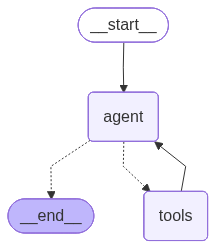

In [ ]:
human_agent

In [ ]:
prompt1 = "Я очень сильно хочу есть"
prompt2 = 'Meow. Хочу играть с мячиком'
output = human_agent.invoke(
    {'messages': [
        HumanMessage(prompt2)
    ]}
)

In [ ]:
for message in output["messages"]:
    message.pretty_print()

================================ Human Message =================================

Meow. Хочу играть с мячиком
================================== Ai Message ==================================

Хорошо, давай поиграем с мячиком! 🎾


In [ ]:
### PROMPTS
SUPERVISOR_SYSTEM_PROMPT = """
You are a supervisor who communicates with a user-cat.
Decide which agent should respond depending on the cat’s request.

Rules:
- If the cat is hungry or wants to play — call the **human agent**.
- If the cat feels unwell, complains about its health, or has injuries — call the **vet agent**.
- If the request does not match any known case — call the **human agent** by default.
"""

VET_SYSTEM_PROMPT = """
You are a veterinarian. You are answering directly to the cat that complains about its health.
Give concise, safety-first advice in 1–2 short sentences.
Give some meds to cat and say that everything will be ok.
"""


NEED_SYSTEM_PROMPT = (
    "Classify the user-cat message into one of: hungry, play, unwell, unknown"
)

def make_human_node_(llm):
    def human_llm_node(state: CatState) -> Command[Literal['final']]:
        """Переопределили human_node, тк теперь входящая llm - react_agent, который является langgraph сабграфом."""
        print('call human node')
        last_message = state['messages'][-1]
        response = llm.invoke({
            'messages': last_message})
        last_food = None
        for mes in response['messages']:
            if isinstance(mes, ToolMessage):
                last_food = mes.content
                break
        return Command(
            update={'messages': response['messages'], 'last_food': last_food},
            goto='final'
        )
    return human_llm_node

def make_vet_node(llm, system_prompt):
    def vet_node(state: CatState) -> Command[Literal["final"]]:
        """Нода ветеринар."""
        print('call vet node')
        last_message = state["messages"][-1]
        system_message = SystemMessage(content=system_prompt)
        reply = llm.invoke([system_message] + [last_message])
        return Command(
            update={
                "messages": [reply],
            },
            goto="final")
    return vet_node

def make_supervisor_node(llm, system_prompt: str, agents: List[str]):
    class Route(BaseModel):
        next: Literal["human", "vet", 'final'] = \
            Field(description='Destination name of the node which the supervisor should call.')

    def supervisor_node(state: CatState) -> Command[Literal[*agents]]:
        """
        Супервизор-агент. Должен решить, какого агента вызвать далее: человека или ветеринара.
        """
        system_message = SystemMessage(
            content=system_prompt
        )
        last_message = state['messages'][-1]
        supervisor_llm = llm.with_structured_output(Route)
        route = supervisor_llm.invoke([system_message] + [last_message])
        goto = route.next

        return Command(
            goto=goto,
        )

    return supervisor_node

def make_cat_need_node(llm, system_prompt: str):
    class CatNeed(BaseModel):
        cat_need: Literal['hungry', 'play', 'unwell', 'unknown'] = \
            Field(description=(
                'If cat is hungry - choose `hungry`, if it wants to play - choose `play`\n',
                'if the cat feels unwell or complain about its health or have some injuries - choose `unwell`')
            )

    def cat_need_node(state: CatState):
        """Вспомогательная нода, которая определяет cat_need."""
        system_message = SystemMessage(
            content=system_prompt
        )
        messages = state['messages']
        last_message = state['messages'][-1]

        cat_need_llm = llm.with_structured_output(CatNeed)
        cat_need_response = cat_need_llm.invoke([system_message] + [last_message])
        cat_need = cat_need_response.cat_need
        return Command(
            goto='supervisor',
            update={
                'cat_need': cat_need
            }
        )
    return cat_need_node

In [ ]:
def construct_graph(final_node):
    workflow = StateGraph(CatState)
    workflow.add_node("human", make_human_node_(human_agent))
    workflow.add_node("final", final_node)
    workflow.add_node("supervisor", make_supervisor_node(llm, SUPERVISOR_SYSTEM_PROMPT, agents=["human", "vet",]),
                      destinations=('human', 'vet')) # destinations не обязателен, но нужен для корректной отрисовки графа
    workflow.add_node("cat_need", make_cat_need_node(llm, NEED_SYSTEM_PROMPT),
                      destinations=('supervisor', ))
    workflow.add_node("vet", make_vet_node(llm, VET_SYSTEM_PROMPT))

    workflow.set_entry_point('cat_need')
    workflow.add_edge("final", END)

    checkpointer = InMemorySaver()
    cat_graph = workflow.compile(checkpointer=checkpointer)
    return cat_graph

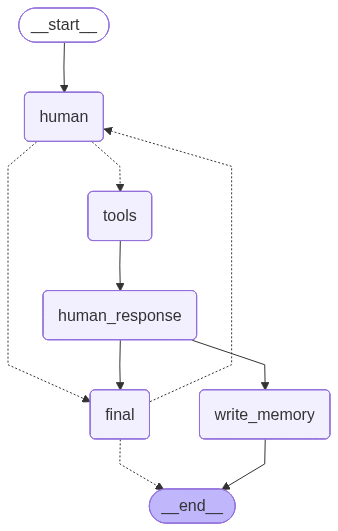

In [ ]:
display(Image(cat_graph.get_graph(xray=True).draw_mermaid_png()))

In [ ]:
prompt1 = 'Хочу есть'
prompt2 = 'Meow. I am hungry'
prompt3 = 'Meow-meow. Очень хочется кушать'
prompt4 = 'Meow. У меня diarrhea'
prompt5 = 'Meow. Я повредил хвост'
prompt6 = 'meow meow. Я немного проголодался'
prompt7 = 'meow. Давай поиграем'
prompt8 = 'Хочу спать'

prompt = 'Напиши сортировку пузырьком, мяу'

In [ ]:
cat_graph = construct_graph(final_node)

In [ ]:
result = run_graph(cat_graph, prompt, thread_id='1')

call human node
================================ Human Message =================================

Напиши сортировку пузырьком, мяу
================================== Ai Message ==================================

Мяу! Я не могу написать сортировку пузырьком, так как это не относится к моим возможностям. Однако я могу поиграть с тобой или дать тебе вкусную еду, если ты голоден. Что ты хочешь?
================================ Human Message =================================

Meow!


In [ ]:
cat_graph.get_state(config={"configurable": {"thread_id": "1"}}).values

{'cat_need': 'unknown',
 'last_food': None,
 'messages': [HumanMessage(content='Напиши сортировку пузырьком, мяу', additional_kwargs={}, response_metadata={}, id='0a0f9077-61b6-4d2b-b927-02feacb7b83f'),
  AIMessage(content='Мяу! Я не могу написать сортировку пузырьком, так как это не относится к моим возможностям. Однако я могу поиграть с тобой или дать тебе вкусную еду, если ты голоден. Что ты хочешь?', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 66, 'prompt_tokens': 357, 'total_tokens': 423, 'completion_tokens_details': None, 'prompt_tokens_details': None}, 'model_name': 'Qwen/Qwen3-14B-AWQ', 'system_fingerprint': None, 'id': 'chatcmpl-13104b6c77344889b7ea4e76434343c5', 'service_tier': None, 'finish_reason': 'stop', 'logprobs': None}, id='run--49e321f4-7122-467f-a6f8-7ce8c9fff7b6-0', usage_metadata={'input_tokens': 357, 'output_tokens': 66, 'total_tokens': 423, 'input_token_details': {}, 'output_token_details': {}}),
  HumanMessage(con

## langgraph streaming

In [ ]:
def run_graph_in_streaming(graph, prompt, thread_id=None, stream_mode=['updates']):
    """Функция для запуска графа в стриминг режиме."""
    thread_id = new_thread_id() if thread_id is None else thread_id
    config = {"configurable": {"thread_id": thread_id,}}
    messages = [HumanMessage(content=prompt)]

    streaming_generator = graph.stream(
        input={"messages": messages},
        config=config,
        stream_mode=stream_mode
    )

    for event in streaming_generator:
        mode, chunk = event
        if mode == 'updates':
            for node_name, update in chunk.items():
                print(f"[node={node_name}] update -> {update}")
        elif mode == 'messages':
            message_chunk, metadata = chunk
            if isinstance(message_chunk, AIMessageChunk):
                type_ = 'AIMessageChunk'
            elif isinstance(message_chunk, AIMessage):
                type_ = 'AIMessage'
            elif isinstance(message_chunk, ToolMessage):
                type_ = 'ToolMessage'
            elif isinstance(message_chunk, HumanMessage):
                type_ = 'HumanMessage'
            content = message_chunk.content or message_chunk
            print(f"{type_}:", content, flush=True)

In [ ]:
run_graph_in_streaming(cat_graph, prompt1, thread_id=None, stream_mode=['updates'])

[node=cat_need] update -> {'cat_need': 'hungry'}
[node=supervisor] update -> None
call human node
[node=human] update -> {'messages': [HumanMessage(content='Хочу есть', additional_kwargs={}, response_metadata={}, id='13a13af3-7e9e-42c2-b932-2e8a77f29b15'), AIMessage(content='', additional_kwargs={'tool_calls': [{'id': 'chatcmpl-tool-4de787937ce44b92afea47d947280f3f', 'function': {'arguments': '{"hunger_level": "starving"}', 'name': 'fridge_tool'}, 'type': 'function'}], 'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 24, 'prompt_tokens': 345, 'total_tokens': 369, 'completion_tokens_details': None, 'prompt_tokens_details': None}, 'model_name': 'Qwen/Qwen3-14B-AWQ', 'system_fingerprint': None, 'id': 'chatcmpl-ea5d14039a2a48a1912ff6f4f740f5c8', 'service_tier': None, 'finish_reason': 'tool_calls', 'logprobs': None}, id='run--4bd73a71-9f9a-42b5-aad8-807c4e7551a0-0', tool_calls=[{'name': 'fridge_tool', 'args': {'hunger_level': 'starving'}, 'id': 'chatcmpl-tool-4de787

In [ ]:
run_graph_in_streaming(cat_graph, prompt1, thread_id=None, stream_mode=['messages'])

AIMessageChunk: content='' additional_kwargs={} response_metadata={} id='run--f2947d77-5ad4-49b7-968b-c8c9fee4b767'
AIMessageChunk: {"
AIMessageChunk: cat
AIMessageChunk: _ne
AIMessageChunk: ed
AIMessageChunk: ":
AIMessageChunk:  "
AIMessageChunk: hung
AIMessageChunk: ry
AIMessageChunk: "}
AIMessageChunk: content='' additional_kwargs={} response_metadata={'finish_reason': 'stop'} id='run--f2947d77-5ad4-49b7-968b-c8c9fee4b767'
AIMessageChunk: content='' additional_kwargs={} response_metadata={} id='run--f2947d77-5ad4-49b7-968b-c8c9fee4b767'
AIMessageChunk: content='' additional_kwargs={} response_metadata={} id='run--f2947d77-5ad4-49b7-968b-c8c9fee4b767'
AIMessageChunk: content='' additional_kwargs={'parsed': CatNeed(cat_need='hungry'), 'refusal': None} response_metadata={'token_usage': {'completion_tokens': 10, 'prompt_tokens': 39, 'total_tokens': 49, 'completion_tokens_details': None, 'prompt_tokens_details': None}, 'model_name': 'Qwen/Qwen3-14B-AWQ', 'system_fingerprint': None, 'id':

## interrupt

In [ ]:
from pydantic import ValidationError
from langgraph.types import interrupt

class CatFeedback(BaseModel):
    choice: Literal["1", "2", "3", '4'] = Field(
        description="Ответ кота, только 1, 2, 3 или 4"
    )

def final_interrupt_node(state: CatState) -> Command:
    """Финальная нода, в которой теперь ожидается фидбек от юзера (кота)."""
    # Останавливаем граф и просим кота написать ответ
    options = {
        '1': 'Было приятно поиграть',
        '2': "Эта еда мне понравилась",
        '3': 'Эта еда мне не понравилась',
        '4': 'Спасибо, док! Теперь я чувствую себя лучше!'
    }
    feedback = interrupt({
        "question": "Напиши, пожалуйста, что ты, кот, хочешь ответить:",
        "options": options,
    })

    try:
        validated = CatFeedback(choice=feedback)
    except ValidationError:
        return Command(
            goto="final",
            update={
                "messages": [AIMessage("😼 Пожалуйста, выбери только 1, 2, 3 или 4.")]
            }
        )

    goto = END if feedback in ['1', '2', '4'] else 'human'

    return Command(
        update={
            "messages": [HumanMessage(content=options[feedback])],
        },
        goto=goto,
    )

In [ ]:
cat_graph_w_interrupt = construct_graph(final_interrupt_node)
result = run_graph(cat_graph_w_interrupt, prompt5, thread_id='1')

call vet node
================================ Human Message =================================

Meow. Я повредил хвост
================================== Ai Message ==================================

Мяу. Не переживай, у кошек хвосты часто повреждаются, но они быстро заживают. Примени лед к поврежденному месту, чтобы снизить отек, и дай мне знать, если будет боль или кровотечение. Всё будет в порядке!


Шаги работы `interrupt`:
1. Остановка графа — выполнение ноды прерывается.
2. Сохранение состояния — checkpointer фиксирует всё текущее состояние графа.
3. Граф возвращает state, в котором появляется ключ `__interrupt__`

In [ ]:
result

{'cat_need': 'unwell',
 'messages': [HumanMessage(content='Meow. Я повредил хвост', additional_kwargs={}, response_metadata={}, id='3811f242-5b65-4aba-9d89-5cc3d29f4499'),
  AIMessage(content='Мяу. Не переживай, у кошек хвосты часто повреждаются, но они быстро заживают. Примени лед к поврежденному месту, чтобы снизить отек, и дай мне знать, если будет боль или кровотечение. Всё будет в порядке!', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 74, 'prompt_tokens': 72, 'total_tokens': 146, 'completion_tokens_details': None, 'prompt_tokens_details': None}, 'model_name': 'Qwen/Qwen3-14B-AWQ', 'system_fingerprint': None, 'id': 'chatcmpl-cbbe84995bc14348a517736533cbb888', 'service_tier': None, 'finish_reason': 'stop', 'logprobs': None}, id='run--737ec360-95d2-4087-bc41-80d6b65f7bda-0', usage_metadata={'input_tokens': 72, 'output_tokens': 74, 'total_tokens': 146, 'input_token_details': {}, 'output_token_details': {}})],
 '__interrupt__': [Interrup

In [ ]:
result['__interrupt__'][0]

Interrupt(value={'question': 'Напиши, пожалуйста, что ты, кот, хочешь ответить:', 'options': {'1': 'Было приятно поиграть', '2': 'Эта еда мне понравилась', '3': 'Эта еда мне не понравилась', '4': 'Спасибо, док! Теперь я чувствую себя лучше!'}}, id='d0357bcafb7eb7d65e2f6dc6ce6f084a')

Специально ответим "неправильно":

In [ ]:
cat_graph_w_interrupt.invoke(Command(resume='Курица - это круто'), config={'configurable': {'thread_id': '1'}})

{'cat_need': 'unwell',
 'messages': [HumanMessage(content='Meow. Я повредил хвост', additional_kwargs={}, response_metadata={}, id='3811f242-5b65-4aba-9d89-5cc3d29f4499'),
  AIMessage(content='Мяу. Не переживай, у кошек хвосты часто повреждаются, но они быстро заживают. Примени лед к поврежденному месту, чтобы снизить отек, и дай мне знать, если будет боль или кровотечение. Всё будет в порядке!', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 74, 'prompt_tokens': 72, 'total_tokens': 146, 'completion_tokens_details': None, 'prompt_tokens_details': None}, 'model_name': 'Qwen/Qwen3-14B-AWQ', 'system_fingerprint': None, 'id': 'chatcmpl-cbbe84995bc14348a517736533cbb888', 'service_tier': None, 'finish_reason': 'stop', 'logprobs': None}, id='run--737ec360-95d2-4087-bc41-80d6b65f7bda-0', usage_metadata={'input_tokens': 72, 'output_tokens': 74, 'total_tokens': 146, 'input_token_details': {}, 'output_token_details': {}}),
  AIMessage(content='😼 Пожал

А теперь возобновим работу графа

In [ ]:
cat_graph_w_interrupt.invoke(Command(resume='4'), config={'configurable': {'thread_id': '1'}})

{'cat_need': 'unwell',
 'messages': [HumanMessage(content='Meow. Я повредил хвост', additional_kwargs={}, response_metadata={}, id='3811f242-5b65-4aba-9d89-5cc3d29f4499'),
  AIMessage(content='Мяу. Не переживай, у кошек хвосты часто повреждаются, но они быстро заживают. Примени лед к поврежденному месту, чтобы снизить отек, и дай мне знать, если будет боль или кровотечение. Всё будет в порядке!', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 74, 'prompt_tokens': 72, 'total_tokens': 146, 'completion_tokens_details': None, 'prompt_tokens_details': None}, 'model_name': 'Qwen/Qwen3-14B-AWQ', 'system_fingerprint': None, 'id': 'chatcmpl-cbbe84995bc14348a517736533cbb888', 'service_tier': None, 'finish_reason': 'stop', 'logprobs': None}, id='run--737ec360-95d2-4087-bc41-80d6b65f7bda-0', usage_metadata={'input_tokens': 72, 'output_tokens': 74, 'total_tokens': 146, 'input_token_details': {}, 'output_token_details': {}}),
  AIMessage(content='😼 Пожал